# 📱 Mobile Phones Market — End-to-End Data Analytics

**Role:** Senior Data Analyst
**Dataset:** `data analytics data set.csv` — e-commerce smartphone listing catalogue (₹ prices)
**Notebook:** full workflow — audit ➜ clean ➜ engineer features ➜ explore ➜ visualise ➜ recommend

---

## 🎯 Business objective
A phone retailer wants to understand its online catalogue: **who wins on price, ratings and
engagement, what specifications justify a price jump, and which phones are the best value for
money at every budget.** This notebook answers those questions with reproducible code.

## 🧭 Analysis roadmap
| # | Stage | What happens |
|---|-------|--------------|
| 1 | Data audit | shape, dtypes, missing values, duplicates, anomalies |
| 2 | Data cleaning | tidy names, fix types, normalise brands, de-duplicate |
| 3 | Feature engineering | camera MP, price-per-GB, value score, engagement rates |
| 4 | Descriptive stats | numeric + categorical profiling |
| 5 | Univariate analysis | distributions of price, rating, specs, brands |
| 6 | Bivariate analysis | correlations, spec-vs-price, brand vs price |
| 7 | Segmentation | price bands & brand deep-dive |
| 8 | Ratings & engagement | what actually drives attention |
| 9 | Outlier detection | IQR + z-score anomalies |
| 10 | Recommendations | best-value picks + key insights |

## 🗂️ Data dictionary
| Column | Meaning |
|---|---|
| Product Name | Listing / model title |
| Brand | Manufacturer |
| Ram | RAM in GB |
| Storage | Internal storage in GB |
| Battery | Battery capacity in mAh |
| Screen_size | Display diagonal in inches |
| Rear_Camera | Rear camera configuration |
| Front_Camera | Selfie camera |
| Rating | Average user rating (out of 5) |
| Rating_Category | Rating band (Excellent / Very Good / Good) |
| Rating_Count | Number of ratings received |
| Review_Count | Number of written reviews |
| Total_Engagements | Rating_Count + Review_Count |
| Offer | Discount offered (%) |
| Price | Selling price in ₹ |
| Price_Range | Price band bucket |

## 0. Setup — libraries & display options

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- display / notebook options ---
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# --- plotting theme ---
sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
DATA_PATH = 'data analytics data set.csv'

print('pandas  :', pd.__version__)
print('numpy   :', np.__version__)
print('seaborn :', sns.__version__)

pandas  : 3.0.5
numpy   : 2.5.2
seaborn : 0.13.2


## 1. Load the dataset

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f'Loaded {raw.shape[0]:,} rows and {raw.shape[1]} columns')
raw.head()

Loaded 652 rows and 17 columns


,Unnamed: 0,Product Name,Brand,Ram,Storage,Battery,Screen_size,Rear_Camera,Front_Camera,Rating,Rating_Category,Rating_Count,Review_Count,Total_Engagements,Offer,Price,Price_Range
0,0,MOTOROLA G04,MOTOROLA,4,64,5000,6.60,16MP Rear Camera,5MP,4.20,Very Good,16753,1042,17795,30,6999,<10K
1,1,Motorola g04s,Motorola,4,64,5000,6.60,50MP Rear Camera,5MP,4.20,Very Good,29634,1640,31274,27,7299,<10K
2,2,Motorola g04s,Motorola,4,64,5000,6.60,50MP Rear Camera,5MP,4.20,Very Good,29634,1640,31274,27,7299,<10K
3,3,Motorola g04s,Motorola,4,64,5000,6.60,50MP Rear Camera,5MP,4.20,Very Good,29634,1640,31274,27,7299,<10K
4,4,POCO C61 - Locked,POCO,4,64,5000,6.71,8MP Rear Camera,5MP,4.10,Very Good,107774,4604,112378,16,7499,<10K


In [3]:
raw.tail(3)

,Unnamed: 0,Product Name,Brand,Ram,Storage,Battery,Screen_size,Rear_Camera,Front_Camera,Rating,Rating_Category,Rating_Count,Review_Count,Total_Engagements,Offer,Price,Price_Range
649,649,Google Pixel 9 Pro,Google,16,256,4700,6.30,50MP + 48MP + 48MP,42MP,4.60,Excellent,479,61,540,18,89999,30K+
650,650,vivo X200 Pro 5G,vivo,16,512,6000,6.78,50MP + 50MP + 200MP,32MP,4.70,Excellent,865,200,1065,6,94999,30K+
651,651,vivo X200 Pro 5G,vivo,16,512,6000,6.78,50MP + 50MP + 200MP,32MP,4.70,Excellent,865,200,1065,6,94999,30K+


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 652 entries, 0 to 651
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         652 non-null    int64  
 1   Product Name       652 non-null    str    
 2   Brand              652 non-null    str    
 3   Ram                652 non-null    int64  
 4   Storage            652 non-null    int64  
 5   Battery            652 non-null    int64  
 6   Screen_size        652 non-null    float64
 7   Rear_Camera        652 non-null    str    
 8   Front_Camera       652 non-null    str    
 9   Rating             652 non-null    float64
 10  Rating_Category    652 non-null    str    
 11  Rating_Count       652 non-null    int64  
 12  Review_Count       652 non-null    int64  
 13  Total_Engagements  652 non-null    int64  
 14  Offer              652 non-null    int64  
 15  Price              652 non-null    int64  
 16  Price_Range        652 non-null    st

## 2. Data audit (BEFORE cleaning)
First rule of analytics: **never trust the raw file.** We profile every column before touching it.

In [5]:
audit = pd.DataFrame({
    'dtype'     : raw.dtypes.astype(str),
    'non_null'  : raw.notna().sum(),
    'nulls'     : raw.isna().sum(),
    'null_%'    : (raw.isna().mean() * 100).round(2),
    'n_unique'  : raw.nunique(),
    'sample'    : [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
})
audit

,dtype,non_null,nulls,null_%,n_unique,sample
Unnamed: 0,int64,652,0,0.00,652,0
Product Name,str,652,0,0.00,164,MOTOROLA G04
Brand,str,652,0,0.00,19,MOTOROLA
Ram,int64,652,0,0.00,5,4
Storage,int64,652,0,0.00,4,64
Battery,int64,652,0,0.00,24,5000
Screen_size,float64,652,0,0.00,26,6.60
Rear_Camera,str,652,0,0.00,53,16MP Rear Camera
Front_Camera,str,652,0,0.00,17,5MP
Rating,float64,652,0,0.00,11,4.20


In [6]:
# --- duplicate detection -------------------------------------------------
# 'Unnamed: 0' is just a row counter, so we compare listings on their real attributes
attr_cols = [c for c in raw.columns if not c.startswith('Unnamed')]

exact_dupes = raw.duplicated(subset=attr_cols).sum()
print(f'Rows              : {len(raw):,}')
print(f'Fully duplicated  : {exact_dupes:,}  ({(exact_dupes/len(raw))*100:.1f}% of the file)')
print(f'Unique listings   : {len(raw) - exact_dupes:,}')
print(f'Unique product names: {raw["Product Name"].nunique():,}')

print('\nExample duplicated listing:')
dupe_examples = (raw[raw.duplicated(subset=attr_cols, keep=False)]
                   .sort_values(['Product Name', 'Price'])
                   .head(8)[['Product Name', 'Brand', 'Ram', 'Storage', 'Price']])
dupe_examples

Rows              : 652
Fully duplicated  : 314  (48.2% of the file)
Unique listings   : 338
Unique product names: 164

Example duplicated listing:


,Product Name,Brand,Ram,Storage,Price
330,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
331,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
333,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
336,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
343,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
347,CMF by Nothing Phone 2 Pro,CMF,8,128,18999
375,CMF by Nothing Phone 2 Pro,CMF,8,256,20999
379,CMF by Nothing Phone 2 Pro,CMF,8,256,20999


In [7]:
# --- categorical value health check -------------------------------------
for col in ['Brand', 'Rating_Category', 'Price_Range']:
    print(f'--- {col}: {raw[col].nunique()} unique values ---')
    print(raw[col].value_counts().to_string())
    print()

--- Brand: 19 unique values ---
Brand
realme      125
vivo         87
Samsung      78
POCO         74
REDMI        60
Motorola     58
OPPO         30
Infinix      29
MOTOROLA     23
Tecno        20
Nothing      18
IQOO         16
Google       15
CMF          12
Xiaomi        3
LAVA          1
itel          1
NOTE          1
Honor         1

--- Rating_Category: 3 unique values ---
Rating_Category
Very Good    603
Excellent     44
Good           5

--- Price_Range: 6 unique values ---
Price_Range
10K-15K    204
15K-20K    115
30K+       112
20K-25K    101
25K-30K     70
<10K        50



In [8]:
# --- numeric profile of the raw file ------------------------------------
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,652.00,325.50,188.36,0.00,162.75,325.50,488.25,651.00
Ram,652.00,7.77,2.52,4.00,6.00,8.00,8.00,16.00
Storage,652.00,190.63,93.51,64.00,128.00,128.00,256.00,512.00
Battery,652.00,"5,281.80",546.95,"4,000.00","5,000.00","5,000.00","5,500.00","7,300.00"
Screen_size,652.00,6.79,1.01,6.10,6.67,6.70,6.77,17.19
Rating,652.00,4.35,0.14,3.90,4.30,4.40,4.40,5.00
Rating_Count,652.00,"28,907.65","53,924.93",6.00,"2,190.50","9,302.00","33,788.75","452,757.00"
Review_Count,652.00,"1,805.78","2,979.53",0.00,156.25,732.00,"2,268.00","23,668.00"
Total_Engagements,652.00,"30,713.43","56,823.82",6.00,"2,352.50","10,100.00","36,685.50","476,425.00"
Offer,652.00,22.55,9.24,4.00,16.00,22.50,29.00,56.00


In [9]:
# --- whitespace / casing check on text columns --------------------------
def text_cols(frame):
    return [c for c in frame.columns if not pd.api.types.is_numeric_dtype(frame[c])]

print('Dirty values detected (raw):')
print('  Brand values with odd casing :', sorted({b for b in raw['Brand'].unique()
                                                   if b != b.title()}))
ws = {c: sorted({str(v) for v in raw[c].unique()
                  if '  ' in str(v) or str(v) != str(v).strip()})
      for c in text_cols(raw)}
print('  Columns with padded / double whitespace:', {c: v for c, v in ws.items() if v})
print('  Screen_size > 8 inches (impossible) :', sorted(raw.loc[raw['Screen_size'] > 8, 'Screen_size'].unique()))
print('  Screen_size flagged rows            :',
      raw.loc[raw['Screen_size'] > 8, ['Product Name', 'Brand', 'Screen_size']].to_dict('records'))

Dirty values detected (raw):
  Brand values with odd casing : ['CMF', 'IQOO', 'LAVA', 'MOTOROLA', 'NOTE', 'OPPO', 'POCO', 'REDMI', 'itel', 'realme', 'vivo']
  Columns with padded / double whitespace: {'Product Name': ['POCO C61  - Locked', 'POCO M7 5G  - Locked']}
  Screen_size > 8 inches (impossible) : [np.float64(17.19)]
  Screen_size flagged rows            : [{'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}, {'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}, {'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}, {'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}, {'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}, {'Product Name': 'Nothing Phone', 'Brand': 'Nothing', 'Screen_size': 17.19}]


### 🔎 Data-quality issues found — and the fix
| # | Issue | Evidence | Action taken |
|---|-------|----------|--------------|
| 1 | `Unnamed: 0` index column leaked into the file | column 1 of the CSV | dropped — it carries no information |
| 2 | **Massive row duplication** | 314 of 652 rows (48.2%) are exact repeats | de-duplicated on all attributes → 338 unique listings |
| 3 | Inconsistent brand casing | `MOTOROLA` vs `Motorola`, `REDMI`, `realme`, `IQOO` | normalised to one canonical label |
| 4 | Padded / double whitespace | `'POCO C61  - Locked'`, `'POCO M7 5G  - Locked'` (and a trailing space in `Storage`) | stripped + internal whitespace collapsed |
| 5 | Impossible screen size | `17.19` inches on 6 Nothing Phone rows | flagged & imputed with the median (6.7 in) |
| 6 | Mis-labelled brand | `NOTE` brand = a Redmi Note 12 5G | mapped to `Redmi` |
| 7 | Zero-review listings | 8 listings have `Review_Count = 0` | kept; rate features divide by `np.nan` to avoid ÷0 |
| 8 | No missing values | 0 nulls in all 17 columns | no imputation needed except the screen anomaly |

## 3. Data cleaning

In [10]:
df = raw.copy()

# 3.1 drop the leaked index column
leaked = [c for c in df.columns if c.startswith('Unnamed') or c.strip() == '']
df = df.drop(columns=leaked)
print('Dropped column(s):', leaked)

# 3.2 tidy column names
df.columns = [c.strip().replace(' ', '_') for c in df.columns]
print('Columns:', df.columns.tolist())

Dropped column(s): ['Unnamed: 0']
Columns: ['Product_Name', 'Brand', 'Ram', 'Storage', 'Battery', 'Screen_size', 'Rear_Camera', 'Front_Camera', 'Rating', 'Rating_Category', 'Rating_Count', 'Review_Count', 'Total_Engagements', 'Offer', 'Price', 'Price_Range']


In [11]:
# 3.3 strip & collapse whitespace in every text column
for c in text_cols(df):
    df[c] = df[c].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)

print('Example after whitespace fix:')
df.loc[df['Product_Name'].str.contains('Locked'), ['Product_Name']].drop_duplicates().head()

Example after whitespace fix:


,Product_Name
4,POCO C61 - Locked
22,POCO M7 5G - Locked


In [12]:
# 3.4 normalise brand labels (single source of truth for the whole analysis)
brand_map = {
    'MOTOROLA': 'Motorola',
    'REDMI'   : 'Redmi',
    'NOTE'    : 'Redmi',      # "NOTE 12 5G" is really a Redmi Note 12 5G
    'realme'  : 'Realme',
    'POCO'    : 'Poco',
    'IQOO'    : 'iQOO',
    'OPPO'    : 'Oppo',
    'LAVA'    : 'Lava',
    'itel'    : 'Itel',
    'vivo'    : 'Vivo',
    'Tecno'   : 'Tecno',
}
df['Brand'] = df['Brand'].replace(brand_map)

print(f'{df["Brand"].nunique()} brands after normalisation:')
print(df['Brand'].value_counts().to_string())

17 brands after normalisation:
Brand
Realme      125
Vivo         87
Motorola     81
Samsung      78
Poco         74
Redmi        61
Oppo         30
Infinix      29
Tecno        20
Nothing      18
iQOO         16
Google       15
CMF          12
Xiaomi        3
Lava          1
Itel          1
Honor         1


In [13]:
# 3.5 remove duplicate listings (keeping the first occurrence)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Removed {before - len(df):,} duplicate rows')
print(f'Clean dataset: {len(df):,} unique listings x {df.shape[1]} columns')

Removed 314 duplicate rows
Clean dataset: 338 unique listings x 16 columns


In [14]:
# 3.6 fix the impossible screen size (data-entry error -> impute with median)
bad_screen = df['Screen_size'] > 8
print(f'Flagged impossible screen sizes: {bad_screen.sum()}')
print(df.loc[bad_screen, ['Product_Name', 'Brand', 'Screen_size']].to_string(index=False))

median_screen = df.loc[~bad_screen, 'Screen_size'].median()
df.loc[bad_screen, 'Screen_size'] = median_screen
print(f'\nImputed with median screen size = {median_screen} inches')
print('Screen size now ranges from', df['Screen_size'].min(), 'to', df['Screen_size'].max(), 'inches')

Flagged impossible screen sizes: 3
 Product_Name   Brand  Screen_size
Nothing Phone Nothing        17.19
Nothing Phone Nothing        17.19
Nothing Phone Nothing        17.19

Imputed with median screen size = 6.7 inches
Screen size now ranges from 6.1 to 6.9 inches


In [15]:
# 3.7 enforce correct dtypes
num_cols = ['Ram', 'Storage', 'Battery', 'Screen_size', 'Rating',
            'Rating_Count', 'Review_Count', 'Total_Engagements', 'Offer', 'Price']
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# ordered categorical for the price band
band_order = ['<10K', '10K-15K', '15K-20K', '20K-25K', '25K-30K', '30K+']
df['Price_Range'] = pd.Categorical(df['Price_Range'], categories=band_order, ordered=True)
df['Rating_Category'] = df['Rating_Category'].astype('category')

print('dtypes after cleaning:')
print(df.dtypes.to_string())
print('\nAny nulls left?', df.isna().sum().sum())

dtypes after cleaning:
Product_Name              str
Brand                     str
Ram                     int64
Storage                 int64
Battery                 int64
Screen_size           float64
Rear_Camera               str
Front_Camera              str
Rating                float64
Rating_Category      category
Rating_Count            int64
Review_Count            int64
Total_Engagements       int64
Offer                   int64
Price                   int64
Price_Range          category

Any nulls left? 0


In [16]:
# --- sanity check: does the Price_Range label agree with the actual Price? ---
bounds = {'<10K': (0, 10_000), '10K-15K': (10_000, 15_000), '15K-20K': (15_000, 20_000),
          '20K-25K': (20_000, 25_000), '25K-30K': (25_000, 30_000), '30K+': (30_000, np.inf)}
band = df['Price_Range'].astype(str)
lo = band.map(lambda b: bounds[b][0])
hi = band.map(lambda b: bounds[b][1])
consistent = ((df['Price'] >= lo) & (df['Price'] < hi)).mean() * 100
print(f'Price_Range label agrees with Price for {consistent:.1f}% of rows')
df.loc[~((df['Price'] >= lo) & (df['Price'] < hi)),
       ['Product_Name', 'Brand', 'Price', 'Price_Range']].head(10)

Price_Range label agrees with Price for 100.0% of rows


,Product_Name,Brand,Price,Price_Range


## 4. Feature engineering
Raw specs are text (`'50MP + 8MP + 2MP'`). We convert them into numeric, analysis-ready features.

In [17]:
# 4.1 camera megapixels -> numbers
def max_mp(text):
    """Largest megapixel value found in a camera description."""
    vals = re.findall(r'(\d+(?:\.\d+)?)\s*MP', str(text))
    return max((float(v) for v in vals), default=np.nan)

df['Rear_Max_MP']  = df['Rear_Camera'].apply(max_mp)
df['Front_MP']     = df['Front_Camera'].apply(max_mp)
df['Rear_Cam_Count'] = df['Rear_Camera'].str.count('MP')   # number of rear lenses

print('Rear camera MP  :', df['Rear_Max_MP'].describe()[['min','50%','max']].to_dict())
print('Front camera MP :', df['Front_MP'].describe()[['min','50%','max']].to_dict())
print('Rear lens count :', sorted(df['Rear_Cam_Count'].unique()))

Rear camera MP  : {'min': 8.0, '50%': 50.0, 'max': 200.0}
Front camera MP : {'min': 2.0, '50%': 16.0, 'max': 50.0}
Rear lens count : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [18]:
# 4.2 5G flag from the product title
df['Is_5G'] = df['Product_Name'].str.contains('5G', case=False, regex=False).astype(int)
print(df['Is_5G'].value_counts().rename({0: '4G / non-5G', 1: '5G'}).to_string())

Is_5G
5G             265
4G / non-5G     73


In [19]:
# 4.3 efficiency / value features
df['Price_per_GB']   = df['Price'] / df['Storage']
df['Price_per_mAh']  = df['Price'] / df['Battery']
df['Price_per_MP']   = df['Price'] / df['Rear_Max_MP']

# how much of the audience bothers to write a review
df['Review_Rate_%'] = (df['Review_Count'] / df['Rating_Count'].replace(0, np.nan)) * 100
# extra engagement beyond a bare rating (reviews add ~2x engagement weight here)
df['Engagement_Lift'] = df['Total_Engagements'] / df['Rating_Count'].replace(0, np.nan)

In [20]:
# 4.4 composite Value Score (0-1) — rating, memory, storage and battery, equally weighted
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

df['Value_Score'] = (0.40 * minmax(df['Rating'])
                   + 0.20 * minmax(df['Ram'])
                   + 0.20 * minmax(df['Storage'])
                   + 0.20 * minmax(df['Battery']))

# value delivered per rupee (scaled for readability)
df['Value_per_Rupee'] = df['Value_Score'] / df['Price'] * 100_000

print('Engineered features added:', [c for c in df.columns if c in
      ['Rear_Max_MP','Front_MP','Rear_Cam_Count','Is_5G','Price_per_GB','Price_per_mAh',
       'Price_per_MP','Review_Rate_%','Engagement_Lift','Value_Score','Value_per_Rupee']])
df[['Product_Name','Brand','Price','Rating','Ram','Storage','Rear_Max_MP','Value_Score']].head()

Engineered features added: ['Rear_Max_MP', 'Front_MP', 'Rear_Cam_Count', 'Is_5G', 'Price_per_GB', 'Price_per_mAh', 'Price_per_MP', 'Review_Rate_%', 'Engagement_Lift', 'Value_Score', 'Value_per_Rupee']


,Product_Name,Brand,Price,Rating,Ram,Storage,Rear_Max_MP,Value_Score
0,MOTOROLA G04,Motorola,6999,4.20,4,64,16.00,0.17
1,Motorola g04s,Motorola,7299,4.20,4,64,50.00,0.17
2,POCO C61 - Locked,Poco,7499,4.10,4,64,8.00,0.13
3,POCO C75 5G,Poco,7699,4.30,4,64,50.00,0.22
4,Infinix Smart 8 Plus,Infinix,7799,4.30,4,128,50.00,0.30


## 5. Descriptive statistics (cleaned data)

In [21]:
df.describe().T[['count','mean','std','min','25%','50%','75%','max']]

,count,mean,std,min,25%,50%,75%,max
Ram,338.00,7.92,2.61,4.00,6.00,8.00,8.00,16.00
Storage,338.00,195.22,97.63,64.00,128.00,128.00,256.00,512.00
Battery,338.00,"5,325.05",587.93,"4,000.00","5,000.00","5,000.00","5,500.00","7,300.00"
Screen_size,338.00,6.70,0.11,6.10,6.67,6.70,6.77,6.90
Rating,338.00,4.35,0.15,3.90,4.30,4.30,4.40,5.00
Rating_Count,338.00,"24,585.88","43,294.16",6.00,"1,738.00","8,444.50","26,103.00","452,757.00"
Review_Count,338.00,"1,555.28","2,478.03",0.00,134.00,593.00,"1,788.00","23,668.00"
Total_Engagements,338.00,"26,141.17","45,693.25",6.00,"1,875.00","8,934.00","27,874.50","476,425.00"
Offer,338.00,22.55,9.42,4.00,15.25,22.00,30.00,56.00
Price,338.00,"22,307.68","13,498.28","6,999.00","12,999.00","18,999.00","26,999.00","94,999.00"


In [22]:
# categorical profile
summary = []
for c in ['Brand', 'Price_Range', 'Rating_Category']:
    summary.append({
        'column'     : c,
        'n_unique'   : df[c].nunique(),
        'top'        : df[c].value_counts().idxmax(),
        'top_count'  : df[c].value_counts().max(),
        'top_share_%': round(df[c].value_counts(normalize=True).max() * 100, 1),
    })
pd.DataFrame(summary)

,column,n_unique,top,top_count,top_share_%
0,Brand,17,Realme,69,20.40
1,Price_Range,6,10K-15K,90,26.60
2,Rating_Category,3,Very Good,308,91.10


In [23]:
# headline KPIs of the catalogue
kpi = pd.Series({
    'Total unique listings' : f'{len(df):,}',
    'Brands'                : df['Brand'].nunique(),
    'Median price'          : f"₹{df['Price'].median():,.0f}",
    'Average price'         : f"₹{df['Price'].mean():,.0f}",
    'Cheapest'              : f"₹{df['Price'].min():,.0f} ({df.loc[df['Price'].idxmin(),'Product_Name']})",
    'Most expensive'        : f"₹{df['Price'].max():,.0f} ({df.loc[df['Price'].idxmax(),'Product_Name']})",
    'Average rating'        : round(df['Rating'].mean(), 2),
    '5G share'              : f"{df['Is_5G'].mean()*100:.1f}%",
    'Average offer'         : f"{df['Offer'].mean():.1f}%",
    'Total catalogue engagement': f"{df['Total_Engagements'].sum():,.0f}",
})
kpi.to_frame('value')

,value
Total unique listings,338
Brands,17
Median price,"₹18,999"
Average price,"₹22,308"
Cheapest,"₹6,999 (MOTOROLA G04)"
Most expensive,"₹94,999 (vivo X200 Pro 5G)"
Average rating,4.35
5G share,78.4%
Average offer,22.6%
Total catalogue engagement,"8,835,714"


## 6. Univariate analysis
Understanding the shape of each variable on its own — centre, spread, skew and outliers.

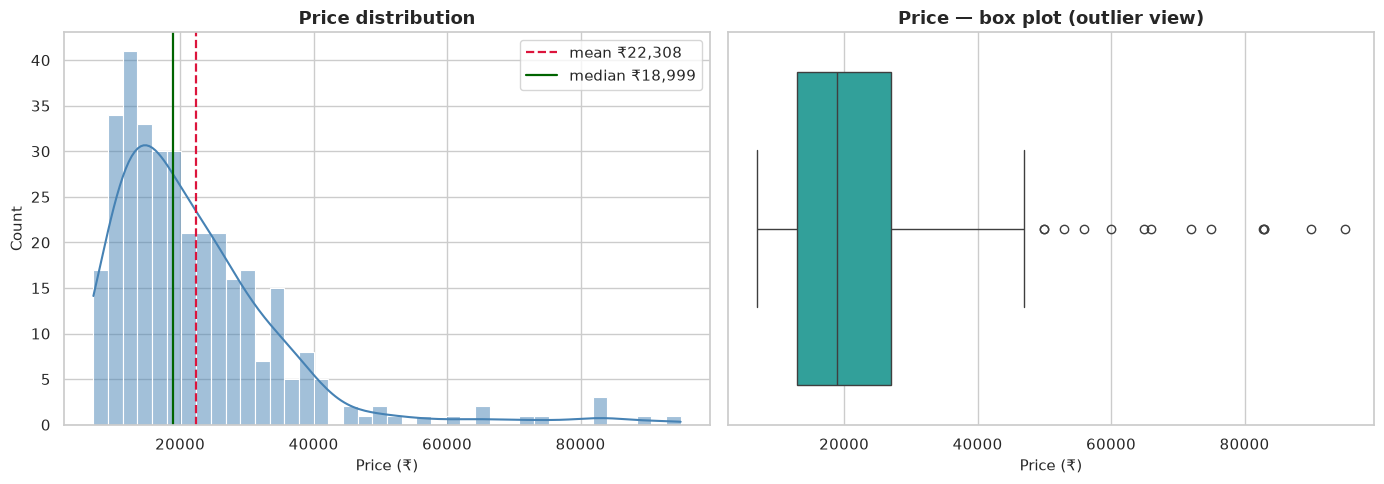

Skewness of Price: 2.37  (right-skewed: a long tail of premium phones)


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Price'], bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['Price'].mean(),   color='crimson', ls='--', lw=1.6, label=f"mean ₹{df['Price'].mean():,.0f}")
axes[0].axvline(df['Price'].median(), color='darkgreen', ls='-', lw=1.6, label=f"median ₹{df['Price'].median():,.0f}")
axes[0].set_title('Price distribution')
axes[0].set_xlabel('Price (₹)'); axes[0].legend()

sns.boxplot(x=df['Price'], ax=axes[1], color='lightseagreen')
axes[1].set_title('Price — box plot (outlier view)')
axes[1].set_xlabel('Price (₹)')
plt.tight_layout(); plt.show()

print(f"Skewness of Price: {df['Price'].skew():.2f}  "
      f"({'right-skewed: a long tail of premium phones' if df['Price'].skew() > 0 else 'left-skewed'})")

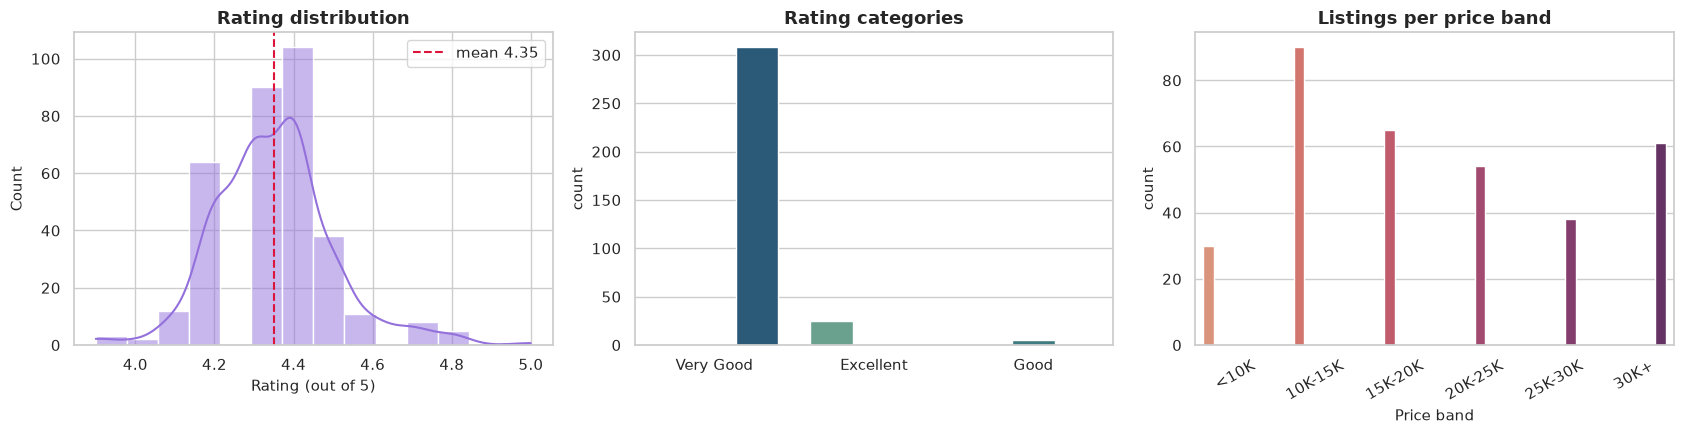

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df['Rating'], bins=14, kde=True, ax=axes[0], color='mediumpurple')
axes[0].axvline(df['Rating'].mean(), color='crimson', ls='--', label=f"mean {df['Rating'].mean():.2f}")
axes[0].set_title('Rating distribution'); axes[0].set_xlabel('Rating (out of 5)'); axes[0].legend()

sns.countplot(data=df, x='Rating_Category', order=df['Rating_Category'].value_counts().index,
              ax=axes[1], hue='Rating_Category', legend=False, palette='crest')
axes[1].set_title('Rating categories'); axes[1].set_xlabel('')

sns.countplot(data=df, x='Price_Range', order=band_order, ax=axes[2], hue='Price_Range',
              legend=False, palette='flare')
axes[2].set_title('Listings per price band'); axes[2].set_xlabel('Price band')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout(); plt.show()

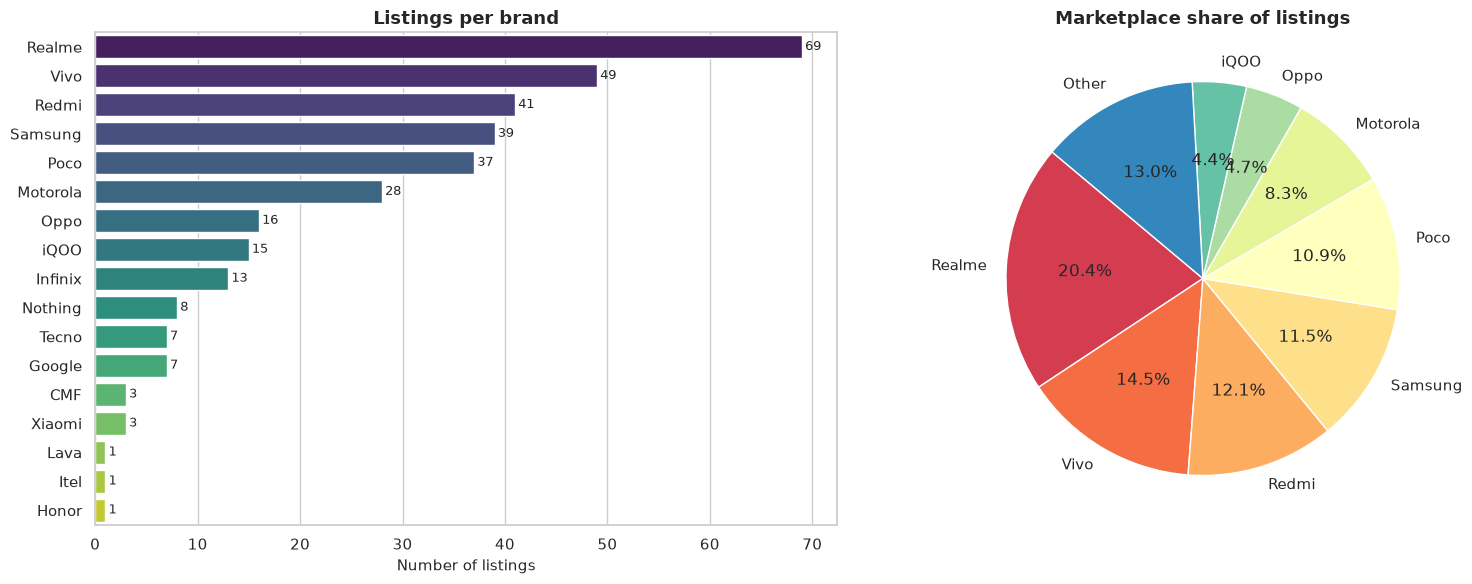

Top brand: Realme with 69 listings (20.4% of catalogue)


In [26]:
brand_counts = df['Brand'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=brand_counts.values, y=brand_counts.index, hue=brand_counts.index,
            legend=False, ax=axes[0], palette='viridis')
axes[0].set_title('Listings per brand'); axes[0].set_xlabel('Number of listings'); axes[0].set_ylabel('')
for i, v in enumerate(brand_counts.values):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=9)

share = brand_counts.head(8)
other = brand_counts.iloc[8:].sum()
pie_data = pd.concat([share, pd.Series({'Other': other})])
axes[1].pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=140,
            colors=sns.color_palette('Spectral', len(pie_data)))
axes[1].set_title('Marketplace share of listings')

plt.tight_layout(); plt.show()

print(f"Top brand: {brand_counts.index[0]} with {brand_counts.iloc[0]} listings "
      f"({brand_counts.iloc[0]/len(df)*100:.1f}% of catalogue)")

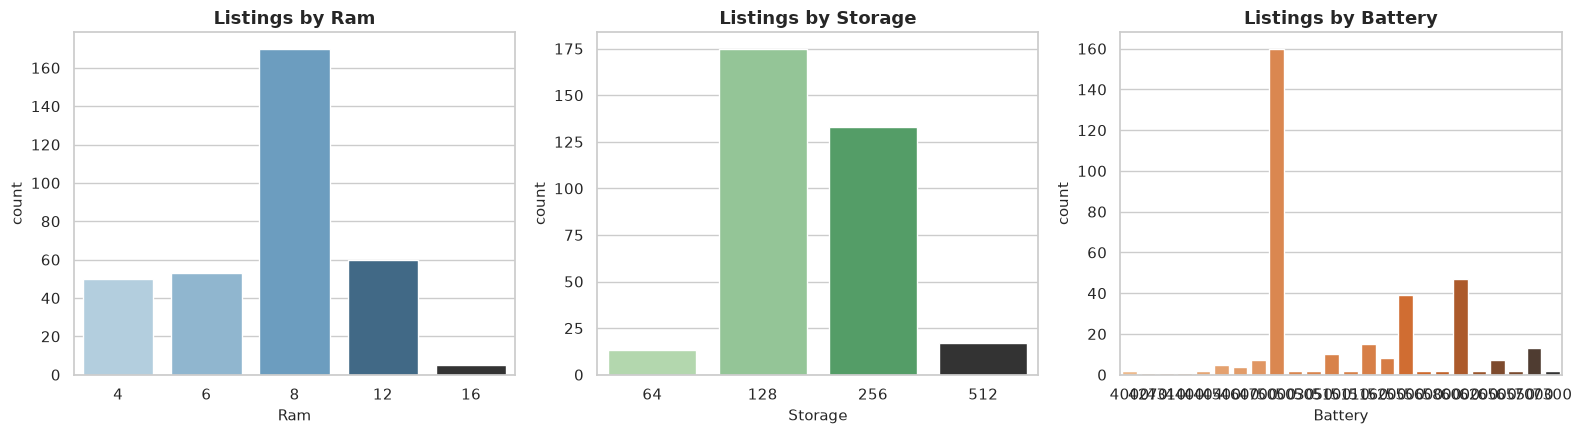

Ram (GB)      -> {4: 50, 6: 53, 8: 170, 12: 60, 16: 5}
Storage (GB)  -> {64: 13, 128: 175, 256: 133, 512: 17}
Battery (mAh) -> {4000: 2, 4270: 1, 4310: 1, 4400: 1, 4404: 2, 4500: 5, 4600: 4, 4700: 7, 5000: 160, 5030: 2, 5050: 2, 5100: 10, 5110: 2, 5160: 15, 5200: 8, 5500: 39, 5600: 2, 5800: 2, 6000: 47, 6200: 2, 6500: 7, 6550: 2, 7000: 13, 7300: 2}


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col, pal in zip(axes, ['Ram', 'Storage', 'Battery'],
                        ['Blues_d', 'Greens_d', 'Oranges_d']):
    order = sorted(df[col].unique())
    sns.countplot(data=df, x=col, order=order, ax=ax, hue=col, legend=False, palette=pal)
    ax.set_title(f'Listings by {col}'); ax.set_xlabel(col)

plt.tight_layout(); plt.show()

print('Ram (GB)      ->', df['Ram'].value_counts().sort_index().to_dict())
print('Storage (GB)  ->', df['Storage'].value_counts().sort_index().to_dict())
print('Battery (mAh) ->', df['Battery'].value_counts().sort_index().to_dict())

## 7. Bivariate & multivariate analysis
Now we look at how variables move together — what actually correlates with price and with ratings.

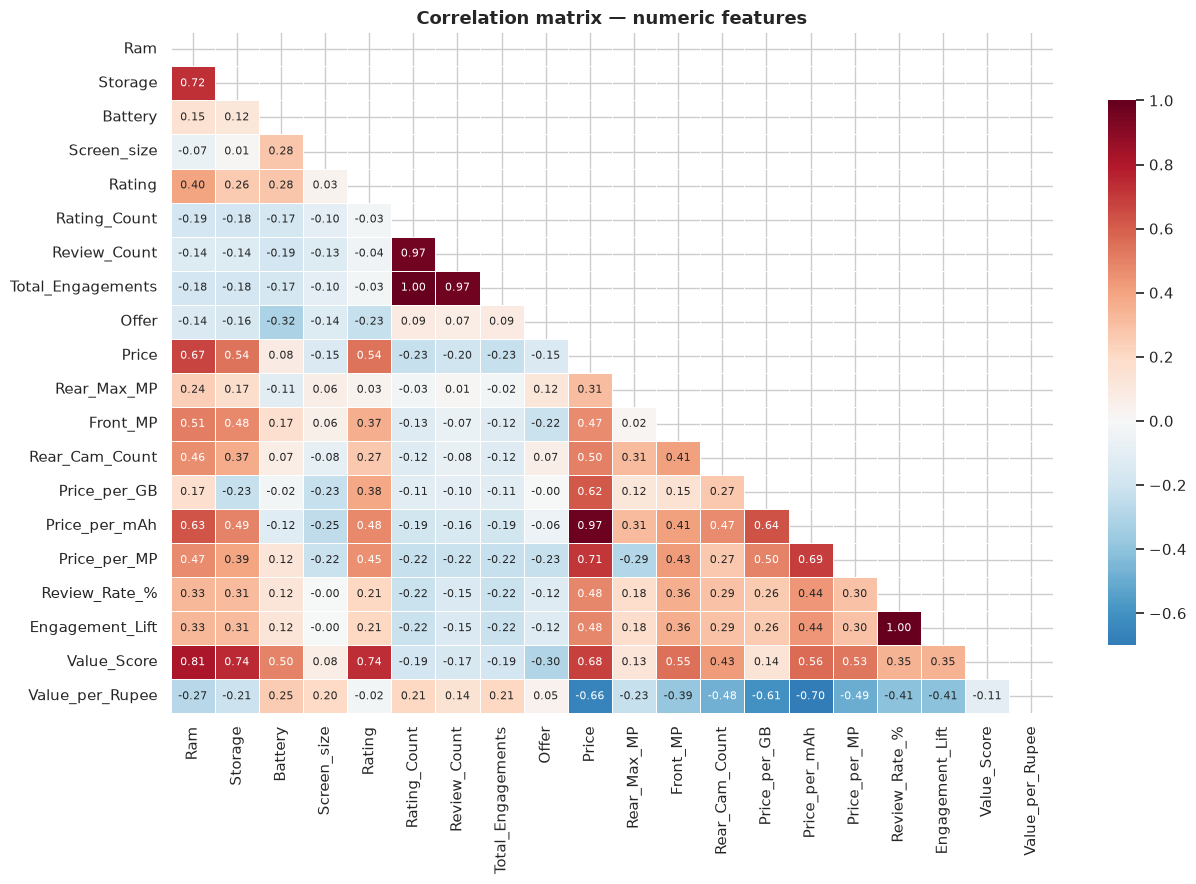

Correlation with Price (strongest first):
Price_per_mAh      0.97
Price_per_MP       0.71
Value_Score        0.68
Ram                0.67
Value_per_Rupee   -0.66
Price_per_GB       0.62
Storage            0.54
Rating             0.54
Rear_Cam_Count     0.50
Engagement_Lift    0.48


In [28]:
num_df = df.select_dtypes(include=[np.number]).drop(columns=['Is_5G'])
corr = num_df.corr()

plt.figure(figsize=(13, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=.5, cbar_kws={'shrink': .8}, annot_kws={'size': 8})
plt.title('Correlation matrix — numeric features')
plt.tight_layout(); plt.show()

price_corr = corr['Price'].drop('Price').sort_values(key=abs, ascending=False)
print('Correlation with Price (strongest first):')
print(price_corr.head(10).round(3).to_string())

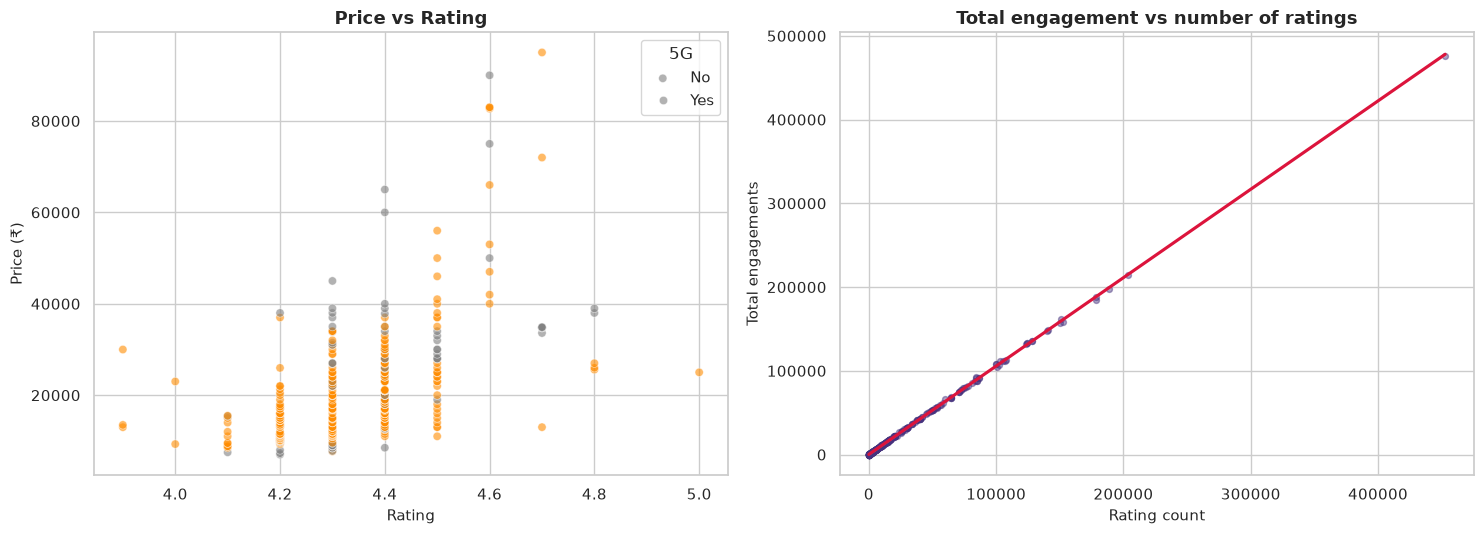

Pearson r (Rating_Count vs Total_Engagements) = 1.000  -> total engagement is almost a 1:1 restatement of rating volume.
Rating vs Price correlation = 0.536 -> pricier phones ARE rated a little higher, but the effect is mild.
Rating scale actually used  = 3.9 - 5.0 (mean 4.35) -> user ratings are heavily compressed.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x='Rating', y='Price', hue='Is_5G', alpha=.6,
                palette={0: 'grey', 1: 'darkorange'}, ax=axes[0])
axes[0].set_title('Price vs Rating'); axes[0].set_ylabel('Price (₹)')
axes[0].legend(title='5G', labels=['No', 'Yes'])

sns.regplot(data=df, x='Rating_Count', y='Total_Engagements', ax=axes[1],
            scatter_kws={'alpha': .45, 's': 18}, line_kws={'color': 'crimson'})
axes[1].set_title('Total engagement vs number of ratings')
axes[1].set_xlabel('Rating count'); axes[1].set_ylabel('Total engagements')

plt.tight_layout(); plt.show()

r = df['Rating_Count'].corr(df['Total_Engagements'])
print(f'Pearson r (Rating_Count vs Total_Engagements) = {r:.3f}  '
      f'-> total engagement is almost a 1:1 restatement of rating volume.')
print(f'Rating vs Price correlation = {df["Rating"].corr(df["Price"]):.3f} '
      f'-> pricier phones ARE rated a little higher, but the effect is mild.')
print(f'Rating scale actually used  = {df["Rating"].min()} - {df["Rating"].max()} '
      f'(mean {df["Rating"].mean():.2f}) -> user ratings are heavily compressed.')

In [30]:
# --- average price by brand, with volume and rating on the same chart -------
brand_stats = (df.groupby('Brand', observed=True)
                 .agg(listings=('Product_Name', 'size'),
                      avg_price=('Price', 'mean'),
                      median_price=('Price', 'median'),
                      avg_rating=('Rating', 'mean'),
                      avg_ram=('Ram', 'mean'),
                      avg_storage=('Storage', 'mean'),
                      avg_battery=('Battery', 'mean'),
                      avg_offer=('Offer', 'mean'),
                      total_engagement=('Total_Engagements', 'sum'),
                      avg_value_score=('Value_Score', 'mean'))
                 .round(2)
                 .sort_values('avg_price', ascending=False))
brand_stats

,listings,avg_price,median_price,avg_rating,avg_ram,avg_storage,avg_battery,avg_offer,total_engagement,avg_value_score
Brand,,,,,,,,,,
Google,7,"57,713.29","59,999.00",4.41,10.86,201.14,"4,654.00",30.00,41196,0.40
Xiaomi,3,"38,665.67","38,999.00",4.37,10.67,426.67,"4,700.00",33.33,3133,0.49
Nothing,8,"28,999.00","28,999.00",4.44,9.50,224.00,"5,000.00",7.12,265609,0.42
Samsung,39,"27,470.59","21,294.00",4.33,7.44,160.82,"5,010.26",27.64,476413,0.32
Vivo,49,"26,999.20","22,999.00",4.46,8.08,207.67,"5,634.69",18.16,2092534,0.44
iQOO,15,"26,626.73","24,390.00",4.53,8.27,204.80,"6,173.33",16.93,55883,0.50
Honor,1,"23,999.00","23,999.00",4.40,8.00,256.00,"5,200.00",40.00,130,0.41
Oppo,16,"22,710.94","21,999.00",4.40,8.00,188.00,"5,706.25",24.06,264393,0.41
Motorola,28,"20,545.43","19,499.00",4.33,8.57,205.71,"5,186.07",20.89,1753238,0.37


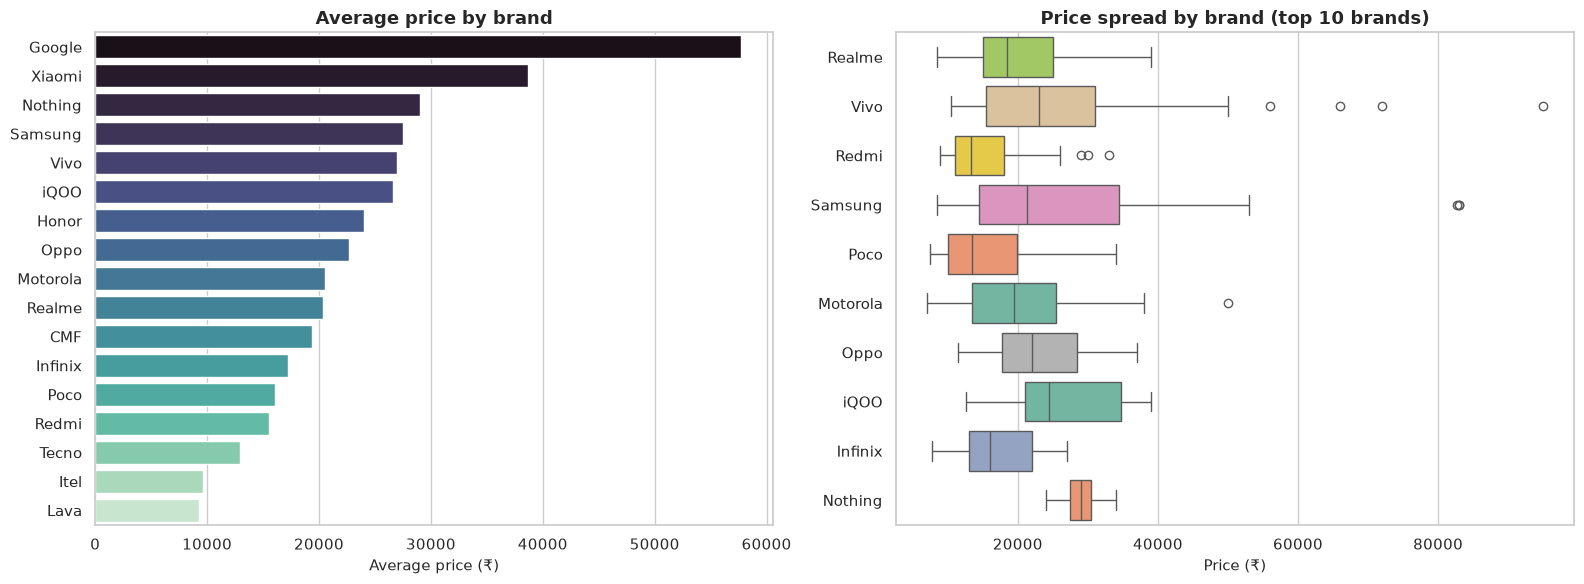

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=brand_stats['avg_price'], y=brand_stats.index, hue=brand_stats.index,
            legend=False, ax=axes[0], palette='mako')
axes[0].set_title('Average price by brand'); axes[0].set_xlabel('Average price (₹)'); axes[0].set_ylabel('')

top10 = df['Brand'].value_counts().head(10).index
sns.boxplot(data=df[df['Brand'].isin(top10)], x='Price', y='Brand',
            order=top10, hue='Brand', legend=False, ax=axes[1], palette='Set2')
axes[1].set_title('Price spread by brand (top 10 brands)')
axes[1].set_xlabel('Price (₹)'); axes[1].set_ylabel('')

plt.tight_layout(); plt.show()

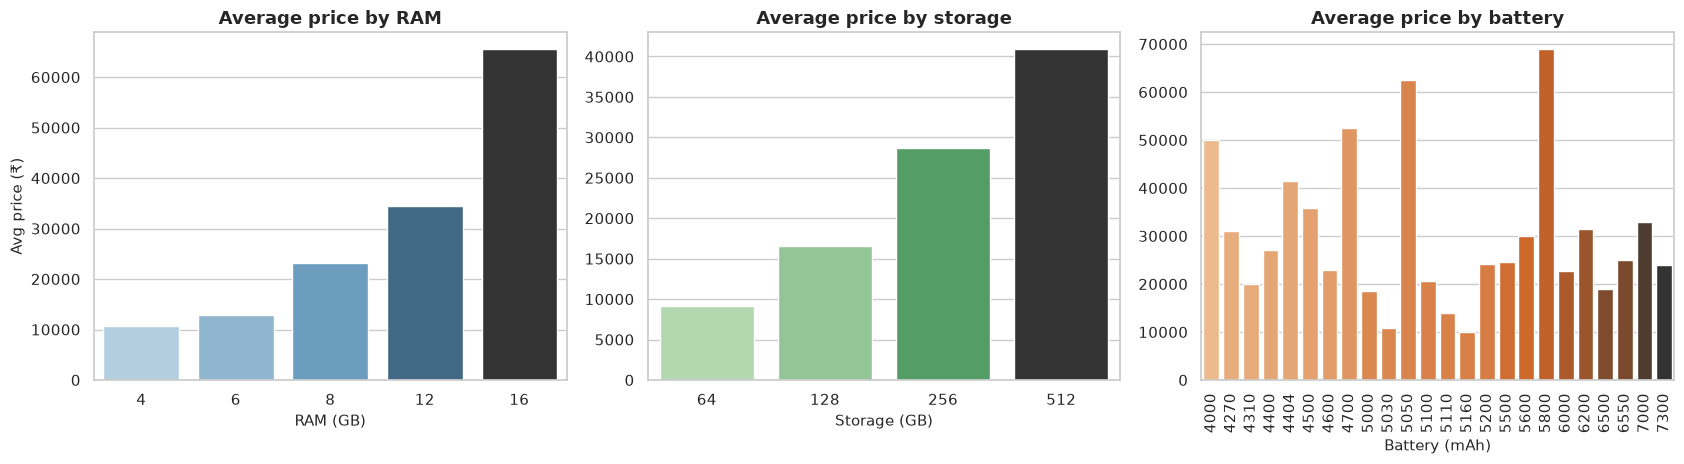

Price premium from 4 GB -> 8 GB RAM : ₹12,531
Price premium from 64 GB -> 256 GB  : ₹19,516

Note: these are ASSOCIATIONS, not causal effects — a memory upgrade always ships with a better chipset, camera and display, so the gap over-states the value of memory alone.


In [32]:
# --- do memory & storage actually raise the price? -------------------------
spec_price = (df.groupby('Ram', observed=True)['Price']
                .agg(['mean', 'median', 'size']).round(0))
storage_price = (df.groupby('Storage', observed=True)['Price']
                   .agg(['mean', 'median', 'size']).round(0))
battery_price = (df.groupby('Battery', observed=True)['Price']
                   .agg(['mean', 'median', 'size']).round(0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.barplot(x=spec_price.index, y=spec_price['mean'], ax=axes[0], hue=spec_price.index,
            legend=False, palette='Blues_d')
axes[0].set_title('Average price by RAM'); axes[0].set_xlabel('RAM (GB)'); axes[0].set_ylabel('Avg price (₹)')

sns.barplot(x=storage_price.index, y=storage_price['mean'], ax=axes[1], hue=storage_price.index,
            legend=False, palette='Greens_d')
axes[1].set_title('Average price by storage'); axes[1].set_xlabel('Storage (GB)'); axes[1].set_ylabel('')

sns.barplot(x=battery_price.index, y=battery_price['mean'], ax=axes[2], hue=battery_price.index,
            legend=False, palette='Oranges_d')
axes[2].set_title('Average price by battery'); axes[2].set_xlabel('Battery (mAh)'); axes[2].set_ylabel('')
axes[2].tick_params(axis='x', rotation=90)

plt.tight_layout(); plt.show()

print('Price premium from 4 GB -> 8 GB RAM :',
      f"₹{spec_price.loc[8,'mean'] - spec_price.loc[4,'mean']:,.0f}")
print('Price premium from 64 GB -> 256 GB  :',
      f"₹{storage_price.loc[256,'mean'] - storage_price.loc[64,'mean']:,.0f}")
print('\nNote: these are ASSOCIATIONS, not causal effects — a memory upgrade always ships with a '
      'better chipset, camera and display, so the gap over-states the value of memory alone.')

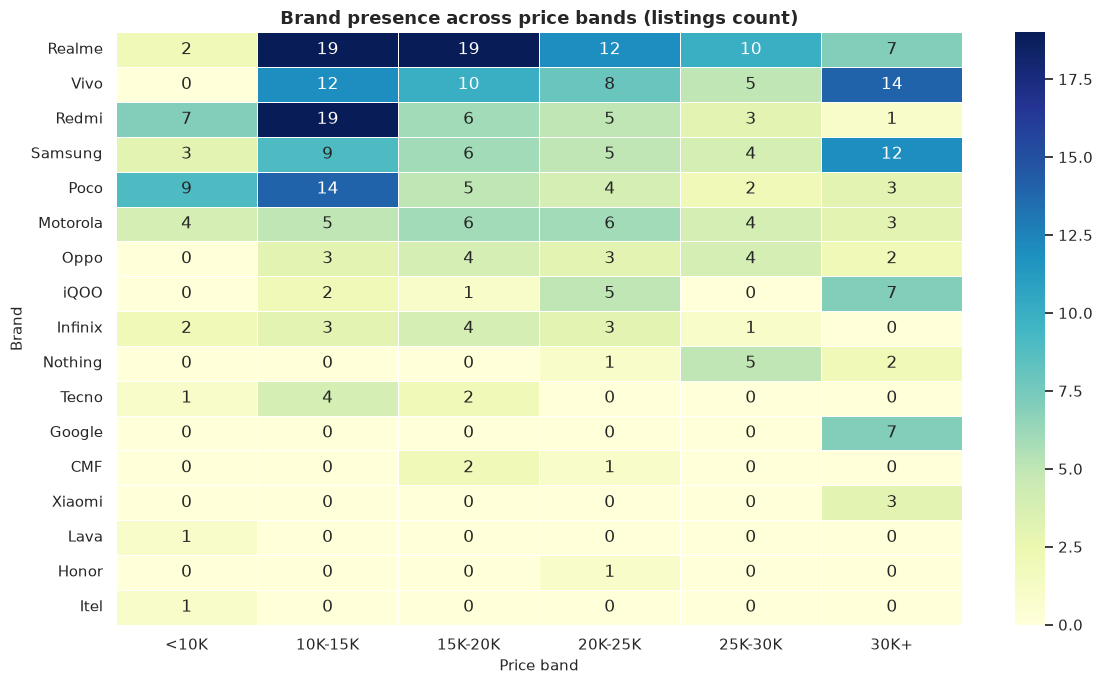

In [33]:
# --- brand x price-band heatmap -------------------------------------------
pivot = pd.crosstab(df['Brand'], df['Price_Range'])
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(12, 7))
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5)
plt.title('Brand presence across price bands (listings count)')
plt.xlabel('Price band'); plt.ylabel('Brand')
plt.tight_layout(); plt.show()

## 8. Price-segment analysis
How does each budget band differ in specs, ratings and competition?

In [34]:
seg = (df.groupby('Price_Range', observed=True)
         .agg(listings=('Product_Name', 'size'),
              min_price=('Price', 'min'),
              avg_price=('Price', 'mean'),
              avg_rating=('Rating', 'mean'),
              avg_ram=('Ram', 'mean'),
              avg_storage=('Storage', 'mean'),
              avg_battery=('Battery', 'mean'),
              avg_rear_mp=('Rear_Max_MP', 'mean'),
              avg_offer=('Offer', 'mean'),
              avg_engagement=('Total_Engagements', 'mean'))
         .round(2))
seg['top_brand'] = df.groupby('Price_Range', observed=True)['Brand']                      .agg(lambda s: s.value_counts().idxmax())
seg

,listings,min_price,avg_price,avg_rating,avg_ram,avg_storage,avg_battery,avg_rear_mp,avg_offer,avg_engagement,top_brand
Price_Range,,,,,,,,,,,
<10K,30,6999,"8,896.77",4.22,4.87,106.67,"5,076.00",44.27,25.50,"32,193.23",Poco
10K-15K,90,10076,"12,721.76",4.28,5.87,137.24,"5,245.56",50.56,24.60,"41,495.27",Redmi
15K-20K,65,15399,"17,689.68",4.33,8.12,177.23,"5,367.85",60.65,23.88,"29,631.49",Realme
20K-25K,54,20499,"22,980.69",4.37,8.81,225.19,"5,289.81",63.89,21.30,"23,255.54",Realme
25K-30K,38,25598,"27,847.05",4.42,9.47,249.26,"5,393.42",60.16,20.11,"15,857.13",Realme
30K+,61,30499,"43,920.67",4.48,10.49,283.28,"5,507.84",60.30,19.31,"5,752.89",Vivo


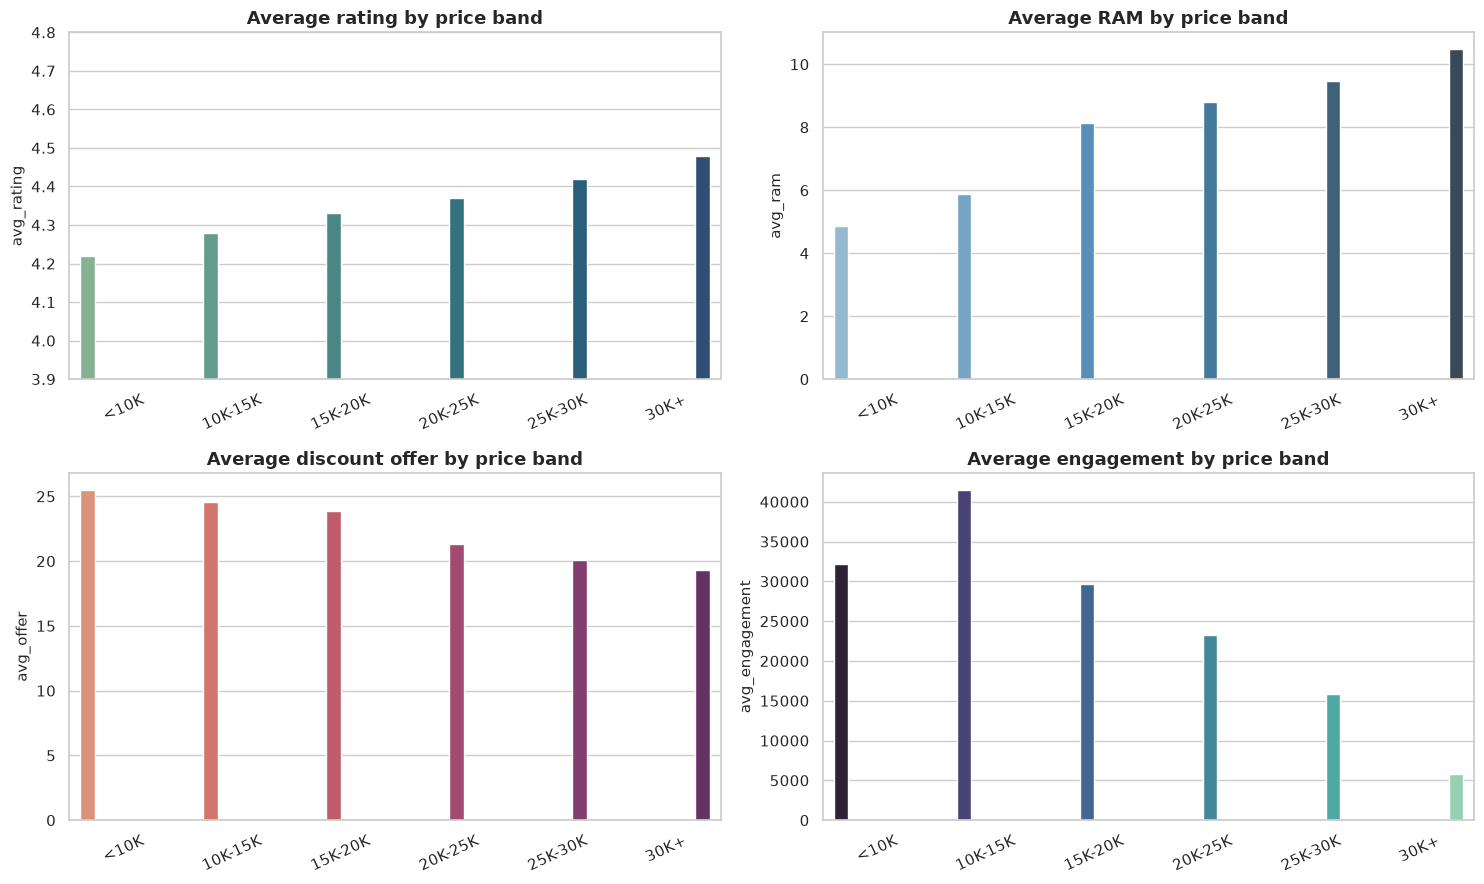

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.barplot(data=seg.reset_index(), x='Price_Range', y='avg_rating', ax=axes[0, 0],
            hue='Price_Range', legend=False, palette='crest')
axes[0, 0].set_title('Average rating by price band'); axes[0, 0].set_xlabel('')
axes[0, 0].set_ylim(3.9, 4.8); axes[0, 0].tick_params(axis='x', rotation=25)

sns.barplot(data=seg.reset_index(), x='Price_Range', y='avg_ram', ax=axes[0, 1],
            hue='Price_Range', legend=False, palette='Blues_d')
axes[0, 1].set_title('Average RAM by price band'); axes[0, 1].set_xlabel('')
axes[0, 1].tick_params(axis='x', rotation=25)

sns.barplot(data=seg.reset_index(), x='Price_Range', y='avg_offer', ax=axes[1, 0],
            hue='Price_Range', legend=False, palette='flare')
axes[1, 0].set_title('Average discount offer by price band'); axes[1, 0].set_xlabel('')
axes[1, 0].tick_params(axis='x', rotation=25)

sns.barplot(data=seg.reset_index(), x='Price_Range', y='avg_engagement', ax=axes[1, 1],
            hue='Price_Range', legend=False, palette='mako')
axes[1, 1].set_title('Average engagement by price band'); axes[1, 1].set_xlabel('')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout(); plt.show()

In [36]:
# which brand dominates each price band, and which band is the most crowded?
crowded = seg['listings'].idxmax()
print(f'Most crowded price band : {crowded} ({int(seg.loc[crowded, "listings"])} listings)')
print(f'Best average rating band: {seg["avg_rating"].idxmax()} ({seg["avg_rating"].max():.2f})')
print(f'Deepest discount band   : {seg["avg_offer"].idxmax()} ({seg["avg_offer"].max():.1f}% average offer)')
print()
print('Top 3 brands in each price band:')
for band in band_order:
    sub = df[df['Price_Range'] == band]
    if len(sub):
        top3 = sub['Brand'].value_counts().head(3).to_dict()
        print(f'  {band:9s} -> {top3}')

Most crowded price band : 10K-15K (90 listings)
Best average rating band: 30K+ (4.48)
Deepest discount band   : <10K (25.5% average offer)

Top 3 brands in each price band:
  <10K      -> {'Poco': 9, 'Redmi': 7, 'Motorola': 4}
  10K-15K   -> {'Redmi': 19, 'Realme': 19, 'Poco': 14}
  15K-20K   -> {'Realme': 19, 'Vivo': 10, 'Redmi': 6}
  20K-25K   -> {'Realme': 12, 'Vivo': 8, 'Motorola': 6}
  25K-30K   -> {'Realme': 10, 'Vivo': 5, 'Nothing': 5}
  30K+      -> {'Vivo': 14, 'Samsung': 12, 'Google': 7}


## 9. Ratings & engagement analysis
Which phones have genuinely earned the crowd's attention (and which are just expensive)?

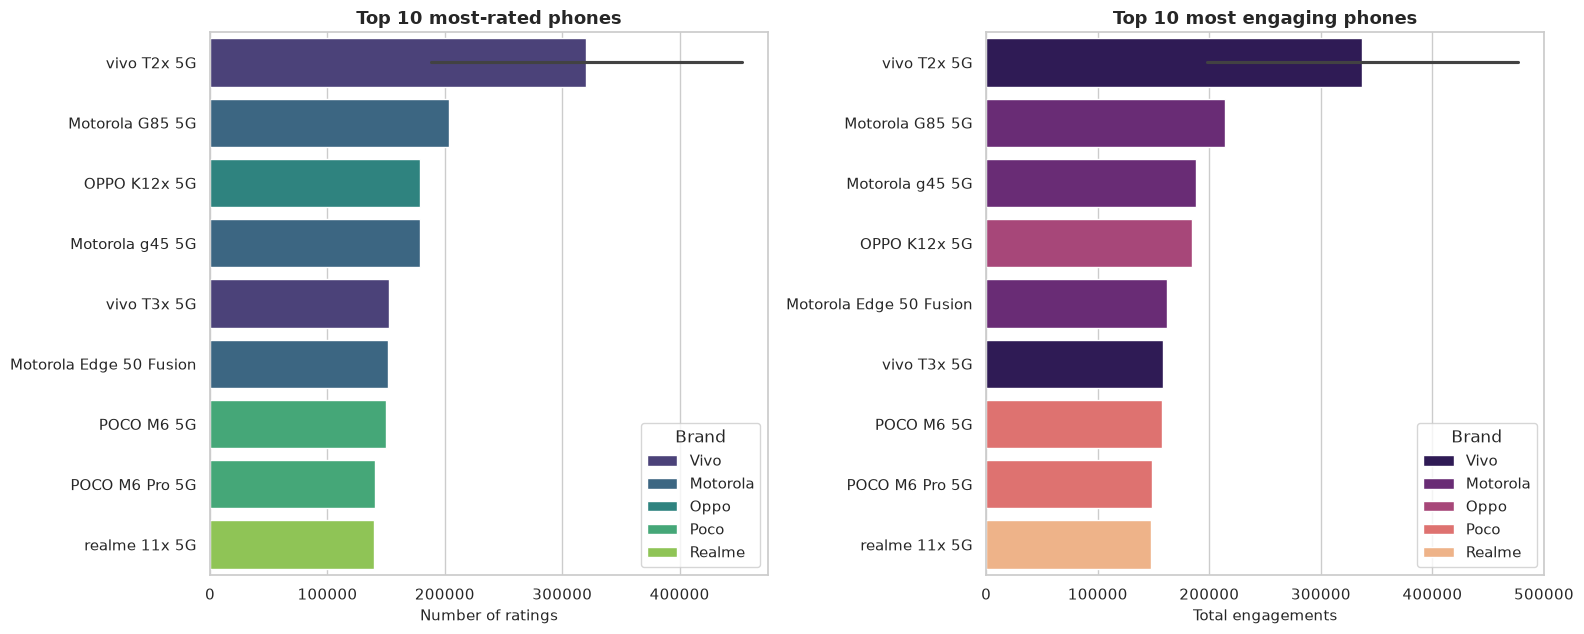

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

top_rated = df.nlargest(10, 'Rating_Count')[['Product_Name', 'Brand', 'Rating', 'Rating_Count']]
sns.barplot(data=top_rated, y='Product_Name', x='Rating_Count', hue='Brand',
            dodge=False, ax=axes[0], palette='viridis')
axes[0].set_title('Top 10 most-rated phones'); axes[0].set_xlabel('Number of ratings'); axes[0].set_ylabel('')

top_eng = df.nlargest(10, 'Total_Engagements')[['Product_Name', 'Brand', 'Total_Engagements']]
sns.barplot(data=top_eng, y='Product_Name', x='Total_Engagements', hue='Brand',
            dodge=False, ax=axes[1], palette='magma')
axes[1].set_title('Top 10 most engaging phones'); axes[1].set_xlabel('Total engagements'); axes[1].set_ylabel('')

plt.tight_layout(); plt.show()

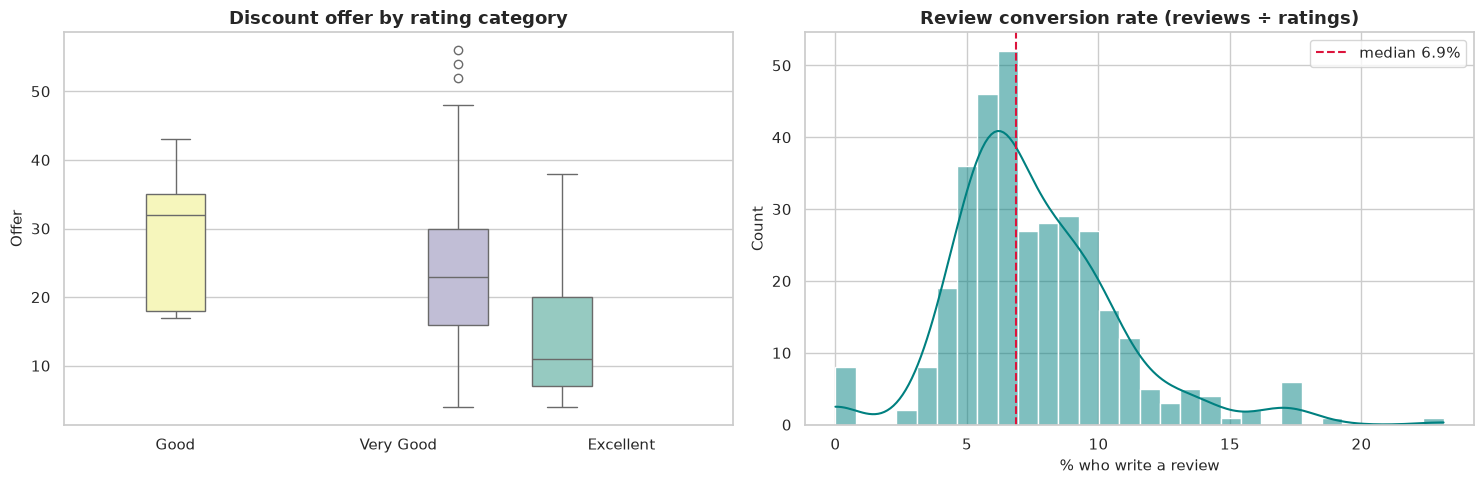

Average offer by rating category (%):
Rating_Category
Excellent   16.16
Good        29.00
Very Good   22.97

Offer vs Rating correlation: -0.234 -> discounting does not improve how the product is rated.


In [38]:
# --- does a bigger "offer" buy a better rating? ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x='Rating_Category', y='Offer', order=['Good', 'Very Good', 'Excellent'],
            hue='Rating_Category', legend=False, ax=axes[0], palette='Set3')
axes[0].set_title('Discount offer by rating category'); axes[0].set_xlabel('')

sns.histplot(df['Review_Rate_%'].dropna(), bins=30, kde=True, ax=axes[1], color='teal')
axes[1].axvline(df['Review_Rate_%'].median(), color='crimson', ls='--',
                label=f"median {df['Review_Rate_%'].median():.1f}%")
axes[1].set_title('Review conversion rate (reviews ÷ ratings)'); axes[1].set_xlabel('% who write a review')
axes[1].legend()

plt.tight_layout(); plt.show()

print('Average offer by rating category (%):')
print(df.groupby('Rating_Category', observed=True)['Offer'].mean().round(2).to_string())
print(f"\nOffer vs Rating correlation: {df['Offer'].corr(df['Rating']):.3f} "
      f"-> discounting does not improve how the product is rated.")

In [39]:
# --- only 1 in N ratings becomes a written review --------------------------
overall_review_rate = df['Review_Count'].sum() / df['Rating_Count'].sum() * 100
print(f'Catalogue-wide review conversion: {overall_review_rate:.1f}% '
      f'({df["Review_Count"].sum():,.0f} reviews from {df["Rating_Count"].sum():,.0f} ratings)')

most_vocal = (df[df['Rating_Count'] > 1000]
                .nlargest(8, 'Review_Rate_%')[['Product_Name', 'Brand', 'Rating_Count',
                                               'Review_Count', 'Review_Rate_%', 'Price']])
print('\nMost "vocal" products (highest review rate, >1000 ratings):')
most_vocal

Catalogue-wide review conversion: 6.3% (525,685 reviews from 8,310,029 ratings)

Most "vocal" products (highest review rate, >1000 ratings):


,Product_Name,Brand,Rating_Count,Review_Count,Review_Rate_%,Price
330,vivo X200 5G,Vivo,1034,182,17.60,65999
218,POCO X7 Pro 5G,Poco,7072,1059,14.97,23999
273,realme 14 Pro+ 5G,Realme,9511,1345,14.14,29999
284,realme 14 Pro+ 5G,Realme,9511,1345,14.14,31999
251,realme P3 Ultra 5G,Realme,1172,158,13.48,26999
238,realme P3 Ultra 5G,Realme,4046,538,13.30,24999
242,POCO X7 Pro 5G,Poco,4052,533,13.15,25999
303,Xiaomi 14 CIVI,Xiaomi,1429,182,12.74,36999


## 10. Outlier & anomaly detection
Outliers are not always errors — in a premium catalogue, an expensive flagship is *legal*.
We separate **statistical outliers** from **data errors**.

In [40]:
def iqr_outliers(series, k=1.5):
    q1, q3 = series.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return series[(series < lo) | (series > hi)], lo, hi

price_out, p_lo, p_hi = iqr_outliers(df['Price'])
eng_out,   e_lo, e_hi = iqr_outliers(df['Rating_Count'])

print(f'Price      : IQR fence = ₹{p_lo:,.0f} .. ₹{p_hi:,.0f}  ->  {len(price_out)} outliers '
      f'({len(price_out)/len(df)*100:.1f}%) — these are genuine premium flagships, kept.')
print(f'Rating_Count: IQR fence = {e_lo:,.0f} .. {e_hi:,.0f} ->  {len(eng_out)} blockbuster outliers.')

# z-score view (mean/std based, useful for a quick second opinion)
z = np.abs((df['Price'] - df['Price'].mean()) / df['Price'].std())
print(f'\n|z| > 3 on Price: {(z > 3).sum()} phone(s)')
df.loc[z > 3, ['Product_Name', 'Brand', 'Price', 'Rating']].sort_values('Price', ascending=False)

Price      : IQR fence = ₹-8,001 .. ₹47,999  ->  14 outliers (4.1%) — these are genuine premium flagships, kept.
Rating_Count: IQR fence = -34,810 .. 62,650 ->  44 blockbuster outliers.

|z| > 3 on Price: 9 phone(s)


,Product_Name,Brand,Price,Rating
337,vivo X200 Pro 5G,Vivo,94999,4.70
336,Google Pixel 9 Pro,Google,89999,4.60
335,Samsung Galaxy S24 Ultra 5G,Samsung,82988,4.60
334,Samsung Galaxy S24 Ultra 5G,Samsung,82979,4.60
333,Samsung Galaxy S24 Ultra 5G,Samsung,82699,4.60
332,Google Pixel 9,Google,74999,4.60
331,vivo X200 5G,Vivo,71999,4.70
330,vivo X200 5G,Vivo,65999,4.60
329,Google Pixel 8 Pro,Google,64999,4.40


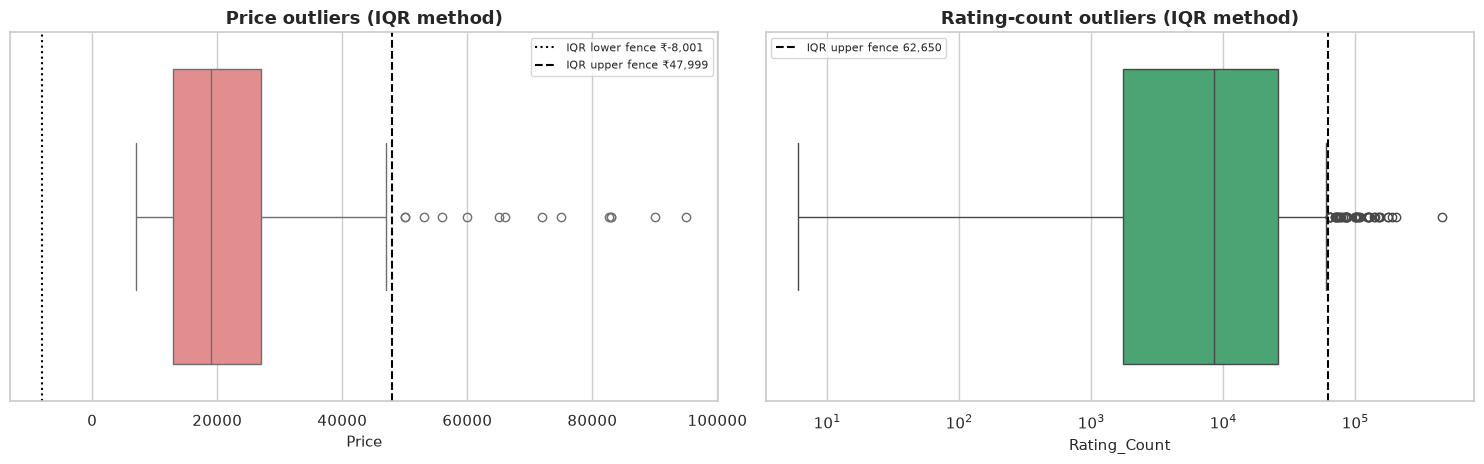

Data-error style anomalies already handled during cleaning:
  • Screen_size = 17.19 in (Nothing Phone) -> imputed with median
  • Product_Name typos: "REDMI Note-14 Pro+ 5G" vs "REDMI Note 14 Pro+ 5G"
  • Duplicate listings removed: 314


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

sns.boxplot(x=df['Price'], ax=axes[0], color='lightcoral')
axes[0].axvline(p_lo, color='black', ls=':', label=f'IQR lower fence ₹{p_lo:,.0f}')
axes[0].axvline(p_hi, color='black', ls='--', label=f'IQR upper fence ₹{p_hi:,.0f}')
axes[0].set_title('Price outliers (IQR method)'); axes[0].legend(fontsize=8)

sns.boxplot(x=df['Rating_Count'], ax=axes[1], color='mediumseagreen')
axes[1].axvline(e_hi, color='black', ls='--', label=f'IQR upper fence {e_hi:,.0f}')
axes[1].set_title('Rating-count outliers (IQR method)'); axes[1].legend(fontsize=8)
axes[1].set_xscale('log')

plt.tight_layout(); plt.show()

print('Data-error style anomalies already handled during cleaning:')
print('  • Screen_size = 17.19 in (Nothing Phone) -> imputed with median')
print('  • Product_Name typos: "REDMI Note-14 Pro+ 5G" vs "REDMI Note 14 Pro+ 5G"')
print('  • Duplicate listings removed:', before - len(df))

In [42]:
# --- consistency check: same product name, different storage variant --------
df['Family'] = (df['Product_Name']
                .str.replace(r'\s*-\s*Locked$', '', regex=True)
                .str.replace(r'\s*-\s*\d+$', '', regex=True)
                .str.strip())

multi = df.groupby('Family', observed=True)['Price'].agg(['nunique', 'min', 'max', 'count'])
multi = multi[multi['nunique'] > 1].sort_values('nunique', ascending=False)
print(f'Product families listed at more than one price: {len(multi)}')
multi.head(10)

Product families listed at more than one price: 101


,nunique,min,max,count
Family,,,,
REDMI 12 5G,9,10971,17990,9
REDMI 14C 5G,9,9499,11499,9
IQOO Neo 10,7,33599,38989,7
Samsung Galaxy A16 5G,6,14498,21294,6
Nothing Phone,6,23999,33999,8
REDMI Note 12 5G,4,12990,15998,4
REDMI Note 13 Pro 5G,4,19999,28999,4
realme Gt 7T,4,31490,38999,4
realme 12x 5G,4,11990,14998,4


## 11. Best-value recommendations
Value = what you get (rating, RAM, storage, battery) per rupee spent.

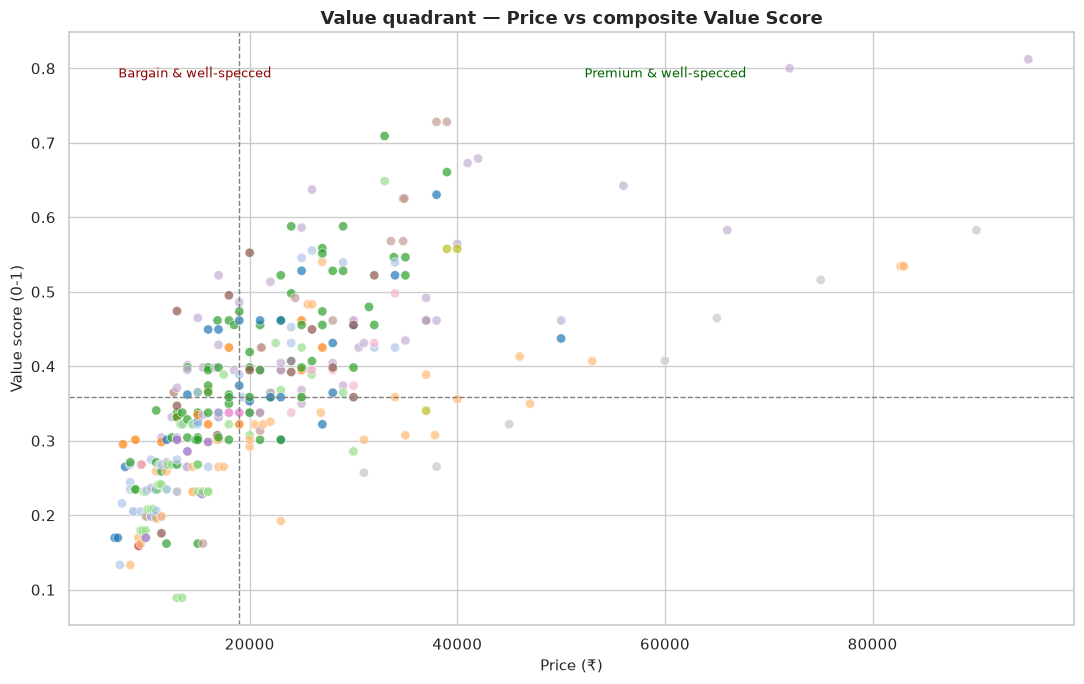

In [43]:
# --- value quadrant: price vs value score ---------------------------------
plt.figure(figsize=(11, 7))
sns.scatterplot(data=df, x='Price', y='Value_Score', hue='Brand', alpha=.7, s=45,
                palette='tab20', legend=False)
plt.axvline(df['Price'].median(), color='grey', ls='--', lw=1)
plt.axhline(df['Value_Score'].median(), color='grey', ls='--', lw=1)
plt.text(df['Price'].max()*0.55, df['Value_Score'].max()*0.97, 'Premium & well-specced',
         fontsize=9, color='darkgreen')
plt.text(df['Price'].min()*1.05, df['Value_Score'].max()*0.97, 'Bargain & well-specced',
         fontsize=9, color='darkred')
plt.title('Value quadrant — Price vs composite Value Score')
plt.xlabel('Price (₹)'); plt.ylabel('Value score (0-1)')
plt.tight_layout(); plt.show()

In [44]:
def recommend(frame, cols, n=8):
    return frame.head(n)[cols].reset_index(drop=True)

stock_cols = ['Product_Name', 'Brand', 'Price', 'Rating', 'Ram', 'Storage',
              'Battery', 'Rear_Max_MP', 'Value_per_Rupee']

# 1) Overall best value: well-rated phones that give the most per rupee
best_value = (df[df['Rating'] >= 4.3]
                .sort_values('Value_per_Rupee', ascending=False))
print('=== 🏆 TOP 8 BEST VALUE PHONES (rating >= 4.3) ===')
display(recommend(best_value, stock_cols))

=== 🏆 TOP 8 BEST VALUE PHONES (rating >= 4.3) ===


,Product_Name,Brand,Price,Rating,Ram,Storage,Battery,Rear_Max_MP,Value_per_Rupee
0,Infinix Smart 8 Plus,Infinix,7799,4.30,4,128,6000,50.00,3.79
1,OPPO K13x 5G 6000mAh and 45W SUPERVOOC Charger...,Oppo,12999,4.70,6,128,6000,50.00,3.65
2,Infinix SMART 8,Infinix,8999,4.30,8,128,5000,50.00,3.35
3,realme C61,Realme,8499,4.40,4,128,5000,32.00,3.19
4,POCO C61,Poco,8499,4.30,6,128,5000,8.00,3.15
5,vivo T4x 5G,Vivo,14999,4.50,8,128,6500,50.00,3.10
6,realme C63 5G Charger in the Box,Realme,10999,4.50,6,128,5000,32.00,3.10
7,vivo T4x 5G,Vivo,16999,4.50,8,256,6500,50.00,3.07


In [45]:
# 2) Cheapest 5G phones
print('=== 📶 TOP 8 CHEAPEST 5G PHONES ===')
display(recommend(df[df['Is_5G'] == 1].sort_values('Price'),
                  ['Product_Name','Brand','Price','Rating','Ram','Storage','Battery'], 8))

# 3) Battery monsters
print('=== 🔋 TOP 8 BATTERY LEADERS ===')
display(recommend(df.sort_values(['Battery','Price'], ascending=[False, True]),
                  ['Product_Name','Brand','Battery','Price','Rating','Ram'], 8))

=== 📶 TOP 8 CHEAPEST 5G PHONES ===


,Product_Name,Brand,Price,Rating,Ram,Storage,Battery
0,POCO C75 5G,Poco,7699,4.30,4,64,5160
1,POCO C75 5G,Poco,8499,4.30,4,128,5160
2,Samsung Galaxy F06 5G,Samsung,8499,4.10,4,64,5000
3,POCO M7 5G - Locked,Poco,8799,4.10,6,128,5160
4,POCO M7 5G,Poco,8799,4.10,6,128,5160
5,Samsung Galaxy A06 5G,Samsung,9282,4.20,4,64,5000
6,LAVA Blaze 5G,Lava,9299,4.00,6,128,5000
7,POCO M7 5G,Poco,9499,4.10,6,128,5160


=== 🔋 TOP 8 BATTERY LEADERS ===


,Product_Name,Brand,Battery,Price,Rating,Ram
0,vivo T4 5G,Vivo,7300,21999,4.50,8
1,vivo T4 5G,Vivo,7300,25999,4.50,12
2,OPPO K13 5G,Oppo,7000,17999,4.50,8
3,OPPO K13 5G,Oppo,7000,19999,4.50,8
4,realme Gt 7T,Realme,7000,31490,4.30,8
5,IQOO Neo 10,iQOO,7000,33599,4.70,8
6,realme Gt 7T,Realme,7000,33885,4.30,12
7,IQOO Neo 10,iQOO,7000,34780,4.70,8


In [46]:
# 4) Best camera for the money (lowest price per megapixel, decent rating)
cam = df[df['Rating'] >= 4.2].sort_values('Price_per_MP')
print('=== 📷 TOP 8 CAMERA VALUE PICKS (lowest ₹ per rear MP) ===')
display(cam[['Product_Name','Brand','Rear_Camera','Rear_Max_MP','Price',
             'Price_per_MP','Rating']].head(8).round(1).reset_index(drop=True))

# 5) Best rated phone under ₹15,000
print('=== 💰 TOP 8 HIGHEST RATED PHONES UNDER ₹15,000 ===')
display(recommend(df[df['Price'] < 15000].sort_values(['Rating','Rating_Count'],
                                                      ascending=[False, False]),
                  ['Product_Name','Brand','Price','Rating','Rating_Count','Ram','Storage'], 8))

=== 📷 TOP 8 CAMERA VALUE PICKS (lowest ₹ per rear MP) ===


,Product_Name,Brand,Rear_Camera,Rear_Max_MP,Price,Price_per_MP,Rating
0,POCO M6 Plus 5G,Poco,108MP + 2MP,108.00,10080,93.30,4.20
1,REDMI Note 13 Pro 5G,Redmi,200MP (OIS) + 8MP + 2MP,200.00,19999,100.00,4.30
2,POCO M6 Plus 5G,Poco,108MP + 2MP,108.00,11499,106.50,4.20
3,REDMI Note 13 Pro 5G,Redmi,200MP (OIS) + 8MP + 2MP,200.00,21999,110.00,4.30
4,Tecno Pova 6 Neo 5G,Tecno,108MP Rear Camera,108.00,11999,111.10,4.30
5,REDMI Note 13 Pro 5G,Redmi,200MP (OIS) + 8MP + 2MP,200.00,22499,112.50,4.30
6,REDMI Note 13 Pro+ 5G,Redmi,200MP (OIS) + 8MP + 2MP,200.00,24999,125.00,4.30
7,POCO X6 Neo 5G,Poco,108MP + 2MP,108.00,13889,128.60,4.20


=== 💰 TOP 8 HIGHEST RATED PHONES UNDER ₹15,000 ===


,Product_Name,Brand,Price,Rating,Rating_Count,Ram,Storage
0,OPPO K13x 5G 6000mAh and 45W SUPERVOOC Charger...,Oppo,12999,4.70,823,6,128
1,OPPO K12x 5G,Oppo,12999,4.50,178548,6,128
2,vivo T3x 5G,Vivo,13999,4.50,152823,6,128
3,vivo T4x 5G,Vivo,14999,4.50,53828,8,128
4,realme C63 5G Charger in the Box,Realme,10999,4.50,21997,6,128
5,vivo Y19 5G,Vivo,12999,4.50,27,6,128
6,vivo T2x 5G,Vivo,12999,4.40,452757,6,128
7,vivo T2x 5G,Vivo,11999,4.40,188472,4,128


In [47]:
# 6) Flagship pick & 7) biggest discount
print('=== 👑 FLAGSHIP PICKS (₹30,000+) ===')
display(recommend(df[df['Price'] >= 30000].sort_values('Rating', ascending=False),
                  ['Product_Name','Brand','Price','Rating','Rating_Count','Ram','Storage'], 6))

print('=== 🎁 BIGGEST DISCOUNTS (offer %) ===')
display(recommend(df.sort_values('Offer', ascending=False),
                  ['Product_Name','Brand','Offer','Price','Rating'], 8))

# 8) best value per brand (silent hero of each brand)
best_by_brand = (df[df['Rating'] >= 4.3]
                   .sort_values('Value_per_Rupee', ascending=False)
                   .groupby('Brand', observed=True)
                   .head(1)
                   .sort_values('Value_per_Rupee', ascending=False))
print('=== ⭐ BEST VALUE PICK PER BRAND ===')
display(best_by_brand[['Brand','Product_Name','Price','Rating','Ram','Storage',
                       'Battery','Value_per_Rupee']].round(4).reset_index(drop=True))

=== 👑 FLAGSHIP PICKS (₹30,000+) ===


,Product_Name,Brand,Price,Rating,Rating_Count,Ram,Storage
0,IQOO Neo 10,iQOO,37990,4.80,15,12,256
1,IQOO Neo 10,iQOO,38989,4.80,15,12,256
2,IQOO Neo 10,iQOO,34780,4.70,35,8,128
3,IQOO Neo 10,iQOO,34895,4.70,35,8,256
4,IQOO Neo 10,iQOO,33599,4.70,35,8,128
5,vivo X200 Pro 5G,Vivo,94999,4.70,865,16,512


=== 🎁 BIGGEST DISCOUNTS (offer %) ===


,Product_Name,Brand,Offer,Price,Rating
0,Samsung Galaxy S23 FE,Samsung,56,34999,4.40
1,OPPO Reno 12 5G,Oppo,54,19999,4.40
2,Samsung Galaxy S23 FE,Samsung,52,37850,4.40
3,Google Pixel 7,Google,48,30999,4.30
4,Google Pixel 8 Pro,Google,43,59999,4.40
5,LAVA Blaze 5G,Lava,43,9299,4.00
6,Google Pixel 8 Pro,Google,42,64999,4.40
7,Samsung Galaxy A35 5G,Samsung,41,19999,4.30


=== ⭐ BEST VALUE PICK PER BRAND ===


,Brand,Product_Name,Price,Rating,Ram,Storage,Battery,Value_per_Rupee
0,Infinix,Infinix Smart 8 Plus,7799,4.30,4,128,6000,3.79
1,Oppo,OPPO K13x 5G 6000mAh and 45W SUPERVOOC Charger...,12999,4.70,6,128,6000,3.65
2,Realme,realme C61,8499,4.40,4,128,5000,3.19
3,Poco,POCO C61,8499,4.30,6,128,5000,3.15
4,Vivo,vivo T4x 5G,14999,4.50,8,128,6500,3.10
5,iQOO,IQOO z9x,12675,4.40,6,128,6000,2.88
6,Itel,itel Color Pro 5G,9598,4.30,6,128,5000,2.79
7,Redmi,REDMI 13C,8888,4.30,4,128,5000,2.64
8,Motorola,Motorola g64 5G,13999,4.30,8,128,6000,2.59
9,Tecno,Tecno Spark 30C 5G,12999,4.30,8,128,5000,2.32


## 12. Key insights

In [48]:
insights = {
  'Catalogue size'            : f'{len(df):,} unique listings across {df["Brand"].nunique()} brands '
                                f'(after removing {before - len(df):,} duplicates)',
  'Price spread'              : f'₹{df["Price"].min():,.0f} to ₹{df["Price"].max():,.0f} '
                                f'(median ₹{df["Price"].median():,.0f}, right-skewed)',
  'Dominant price band'       : f'{seg["listings"].idxmax()} holds the most listings '
                                f'({int(seg["listings"].max())})',
  'Brand concentration'       : f'{brand_counts.index[0]} + {brand_counts.index[1]} = '
                                f'{(brand_counts.iloc[0]+brand_counts.iloc[1])/len(df)*100:.0f}% of all listings',
  'Price vs rating'           : f'corr(Price, Rating) = {df["Price"].corr(df["Rating"]):+.3f} — '
                                f'pricier phones are rated higher, but only mildly: the whole '
                                f'scale spans just {df["Rating"].min()}-{df["Rating"].max()}',
  'Specs that move the price' : 'corr(Price, RAM) = '
                                f'{df["Price"].corr(df["Ram"]):+.3f}, '
                                f'corr(Price, Storage) = {df["Price"].corr(df["Storage"]):+.3f}, '
                                f'corr(Price, Battery) = {df["Price"].corr(df["Battery"]):+.3f}',
  'Engagement driver'         : f'corr(Rating_Count, Total_Engagements) = '
                                f'{df["Rating_Count"].corr(df["Total_Engagements"]):+.3f} '
                                f'— attention is driven by rating volume',
  'Review conversion'         : f'only {overall_review_rate:.1f}% of ratings turn into a written review',
  'Discounting is ineffective': f'corr(Offer, Rating) = {df["Offer"].corr(df["Rating"]):+.3f} '
                                f'— bigger discounts do not produce better-rated phones',
  '5G penetration'            : f'{df["Is_5G"].mean()*100:.0f}% of the catalogue is 5G',
  'Cheapest 5G'               : f'₹{df[df["Is_5G"]==1]["Price"].min():,.0f} '
                                f'({df[df["Is_5G"]==1].nsmallest(1,"Price")["Product_Name"].iloc[0]})',
  'Best value score holder'   : f'{best_value.iloc[0]["Product_Name"]} '
                                f'(₹{best_value.iloc[0]["Price"]:,.0f}, rating {best_value.iloc[0]["Rating"]})',
}
for k, v in insights.items():
    print(f'• {k:28s}: {v}')

• Catalogue size              : 338 unique listings across 17 brands (after removing 314 duplicates)
• Price spread                : ₹6,999 to ₹94,999 (median ₹18,999, right-skewed)
• Dominant price band         : 10K-15K holds the most listings (90)
• Brand concentration         : Realme + Vivo = 35% of all listings
• Price vs rating             : corr(Price, Rating) = +0.536 — pricier phones are rated higher, but only mildly: the whole scale spans just 3.9-5.0
• Specs that move the price   : corr(Price, RAM) = +0.674, corr(Price, Storage) = +0.544, corr(Price, Battery) = +0.080
• Engagement driver           : corr(Rating_Count, Total_Engagements) = +1.000 — attention is driven by rating volume
• Review conversion           : only 6.3% of ratings turn into a written review
• Discounting is ineffective  : corr(Offer, Rating) = -0.234 — bigger discounts do not produce better-rated phones
• 5G penetration              : 78% of the catalogue is 5G
• Cheapest 5G                 : ₹7,699 (P

### 📌 What the numbers say

1. **The catalogue is mid-market, not budget-only.** 54.7% of listings sit below ₹20,000, and
   ₹10K–15K is the single most crowded band (26.6% of all listings). ₹30K+ accounts for 18% of
   listings and carries the highest average rating of any band.
2. **Price and rating move together — but gently.** `corr(Price, Rating) = +0.54`, and average
   rating climbs monotonically across bands (4.22 below ₹10K ➜ 4.48 at ₹30K+). So premium phones
   *are* better liked. The catch is that the observed rating scale spans only **3.9 to 5.0** —
   user ratings here are compressed and uniformly positive, which makes rating a weak
   differentiator between products.
3. **RAM and storage drive price; battery does not.** `corr(Price, RAM) = +0.67`,
   `corr(Price, Storage) = +0.54`, but `corr(Price, Battery) = +0.08`. The market pays for memory
   configuration (the 4/64 ➜ 12/512 SKU ladder), not for a bigger battery.
4. **Attention is a volume game.** `corr(Rating_Count, Total_Engagements) = +1.00` — on this
   catalogue "engagement" is almost a 1:1 restatement of rating volume, and only **6.3%** of
   ratings ever become a written review. Optimise for *the number of ratings*, not review length.
5. **Discounts do not buy love.** `corr(Offer, Rating) = -0.23`: the deepest-discount band
   (<₹10K, 25.5% average offer) has the **lowest** average rating (4.22). Discounting shifts
   units, it does not shift sentiment.
6. **There is a clear value sweet spot.** Every high-value phone (rating >= 4.3 by value-per-rupee)
   sits between **₹8,000 and ₹20,000** — Infinix Smart 8 Plus, OPPO K13x 5G, realme C61,
   vivo T4x 5G and similar. These are the models worth featuring on the storefront.
7. **Data hygiene mattered more than any model.** **314 of the 652 raw rows (48.2%) were exact
   duplicates.** Without de-duplication, every brand average and brand ranking would have been
   silently weighted toward whichever SKU happened to be repeated most often in the scrape.

## 13. Export the clean, analysis-ready dataset

In [49]:
export_cols = [c for c in df.columns if c != 'Family'] 
df[export_cols].to_csv('mobile_phones_cleaned.csv', index=False)
print('Saved -> mobile_phones_cleaned.csv')
print('Shape :', df[export_cols].shape)
print('Columns:', df[export_cols].columns.tolist())

Saved -> mobile_phones_cleaned.csv
Shape : (338, 27)
Columns: ['Product_Name', 'Brand', 'Ram', 'Storage', 'Battery', 'Screen_size', 'Rear_Camera', 'Front_Camera', 'Rating', 'Rating_Category', 'Rating_Count', 'Review_Count', 'Total_Engagements', 'Offer', 'Price', 'Price_Range', 'Rear_Max_MP', 'Front_MP', 'Rear_Cam_Count', 'Is_5G', 'Price_per_GB', 'Price_per_mAh', 'Price_per_MP', 'Review_Rate_%', 'Engagement_Lift', 'Value_Score', 'Value_per_Rupee']


---
### ▶️ How to reuse this notebook
1. Put `data analytics data set.csv` in the same folder as this notebook.
2. Run **Kernel ▸ Restart & Run All**.
3. `mobile_phones_cleaned.csv` is written with all cleaned + engineered features.

**Tools:** Python · pandas · NumPy · Matplotlib · Seaborn